# Step 1.7 — Explore the NYC 311 housing sample (EDA)

**Goal:** understand the data before we use it. We only look here: no cleaning, no labels
(the mapping to our 6 categories is Step 1.8).

**Data**, made by `ml/sample_311.py` (both files are git-ignored):
- `311_hpd_sample.csv`: a 10% sample (`unique_key` ends in 7) of the HPD requests created from
  2025-10-01 to 2026-09-30, 14 columns.
- `311_hpd_population_counts.csv`: **all** HPD requests in the same window, counted per
  complaint type, descriptor and additional details.

Source: NYC Open Data, "311 Service Requests from 2020 to Present" (`erm2-nwe9`),
Momo's export of 2026-10-22.

**Run all cells:** `uv run jupyter nbconvert --to notebook --execute --inplace
ml/notebooks/01_explore_311.ipynb`, or "Run All" in VS Code with the `.venv` kernel.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# The notebook runs from its own folder (VS Code, nbconvert) or from the repo root: find the root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RAW = ROOT / "ml" / "data" / "raw"
DATE_COLUMNS = ["created_date", "closed_date", "resolution_action_updated_date"]

# Read every value as text. keep_default_na=False: only a truly empty cell is missing.
# By default pandas also turns the text "N/A" into missing, and here we want to SEE it
sample = pd.read_csv(RAW / "311_hpd_sample.csv", dtype=str, keep_default_na=False, na_values=[""])
counts = pd.read_csv(RAW / "311_hpd_population_counts.csv", keep_default_na=False)
for column in DATE_COLUMNS:
    sample[column] = pd.to_datetime(sample[column], format="ISO8601")

# One quiet style for all charts: one blue for the data, gray for axes and grid
BLUE, INK, MUTED = "#2a78d6", "#0b0b0b", "#52514e"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "axes.titlecolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.axisbelow": True,
        "grid.color": "#e5e4e0",
    }
)
pd.set_option("display.max_colwidth", 80)

print(f"sample: {len(sample):,} rows x {sample.shape[1]} columns")
print(f"population: {counts['n'].sum():,} rows in {len(counts)} (type, descriptor, details) groups")

sample: 90,405 rows x 14 columns
population: 904,284 rows in 174 (type, descriptor, details) groups


## 1. Columns: what is in each one?

For every column: how many different values, how much is missing, and one example.
The text `N/A` is counted apart: it is a value that *means* "missing"
(a **disguised missing value**).

In [2]:
overview = pd.DataFrame(
    {
        "different values": sample.nunique(),
        "% empty": (sample.isna().mean() * 100).round(1),
        "% 'N/A' text": ((sample == "N/A").mean() * 100).round(1),
        "example (first row)": sample.iloc[0],
    }
)
overview

,different values,% empty,% 'N/A' text,example (first row)
unique_key,90405,0.0,0.0,70597767
created_date,83395,0.0,0.0,2026-09-30 23:46:37
closed_date,59554,3.1,0.0,2026-10-02 13:53:15
agency,1,0.0,0.0,HPD
complaint_type,13,0.0,0.0,WATER LEAK
descriptor,56,0.0,0.0,DAMP SPOT
descriptor_2,132,0.0,4.3,FROM WALL OR CEILING
location_type,1,0.0,0.0,RESIDENTIAL BUILDING
incident_zip,184,0.0,0.0,10033
borough,5,0.0,0.0,MANHATTAN


In [3]:
# Columns with only a few different values: show them all
for column in ["status", "location_type", "borough", "open_data_channel_type"]:
    print(sample[column].value_counts().to_string(), end="\n\n")

status
Closed    87626
Open       2779

location_type
RESIDENTIAL BUILDING    90405

borough
BRONX            30235
BROOKLYN         26684
MANHATTAN        20422
QUEENS           11702
STATEN ISLAND     1362

open_data_channel_type
ONLINE    46941
PHONE     36762
MOBILE     6702



## 2. Date range and requests per month

Heating complaints should rise in winter (NYC's heat season is October to May).
If they do, a sample of only some months would be **biased**.

created from 2025-10-01 01:23:52 to 2026-09-30 23:46:37


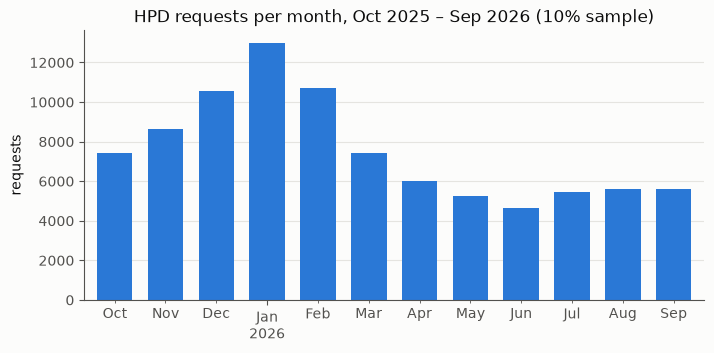

created_date,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09
requests,7446.0,8624.0,10583.0,12971.0,10734.0,7439.0,6016.0,5249.0,4670.0,5472.0,5617.0,5584.0
% heat/hot water,42.9,55.5,60.3,61.7,54.9,40.1,32.5,18.7,9.6,7.7,6.6,8.6


In [4]:
print("created from", sample["created_date"].min(), "to", sample["created_date"].max())

month = sample["created_date"].dt.to_period("M")
per_month = pd.DataFrame(
    {
        "requests": month.value_counts().sort_index(),
        "% heat/hot water": (
            (sample["complaint_type"] == "HEAT/HOT WATER").groupby(month).mean() * 100
        ).round(1),
    }
)

ax = per_month["requests"].plot.bar(color=BLUE, width=0.7, figsize=(8, 3.5))
ax.set(
    title="HPD requests per month, Oct 2025 – Sep 2026 (10% sample)", xlabel="", ylabel="requests"
)
ax.grid(axis="y")
plt.show()
per_month.T

## 3. Complaint types (level 1)

These are the classes a classifier would learn first. Look at how different the sizes are.

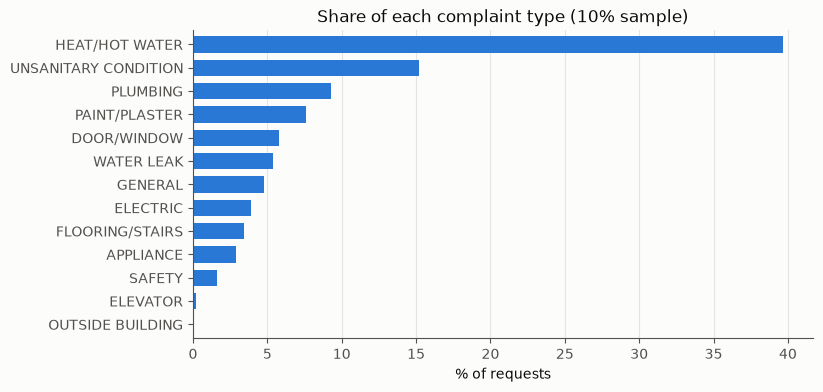

,requests,%
complaint_type,,
HEAT/HOT WATER,35900,39.7
UNSANITARY CONDITION,13716,15.2
PLUMBING,8408,9.3
PAINT/PLASTER,6857,7.6
DOOR/WINDOW,5260,5.8
WATER LEAK,4841,5.4
GENERAL,4339,4.8
ELECTRIC,3567,3.9
FLOORING/STAIRS,3071,3.4


In [5]:
types = sample["complaint_type"].value_counts().to_frame("requests")
types["%"] = (types["requests"] / len(sample) * 100).round(1)

ax = types["%"].sort_values().plot.barh(color=BLUE, width=0.7, figsize=(8, 4))
ax.set(title="Share of each complaint type (10% sample)", xlabel="% of requests", ylabel="")
ax.grid(axis="x")
plt.show()
types

## 4. Descriptors (level 2) and additional details (level 3)

Each complaint type is split into descriptors, and each descriptor into additional details.
Step 1.8 maps this tree to our 6 categories. The full tree, with counts, is in
`311_hpd_population_counts.csv` (open it in VS Code).

In [6]:
levels = (
    sample.groupby("complaint_type")
    .agg(
        requests=("unique_key", "size"),
        descriptors=("descriptor", "nunique"),
        details=("descriptor_2", "nunique"),
        biggest_descriptor=("descriptor", lambda s: s.value_counts().index[0]),
    )
    .sort_values("requests", ascending=False)
)
levels

,requests,descriptors,details,biggest_descriptor
complaint_type,,,,
HEAT/HOT WATER,35900,2,4,ENTIRE BUILDING
UNSANITARY CONDITION,13716,4,12,PESTS
PLUMBING,8408,8,33,WATER SUPPLY
PAINT/PLASTER,6857,6,7,WALL
DOOR/WINDOW,5260,5,9,DOOR
WATER LEAK,4841,3,2,HEAVY FLOW
GENERAL,4339,7,16,BELL/BUZZER/INTERCOM
ELECTRIC,3567,5,15,POWER OUTAGE
FLOORING/STAIRS,3071,2,13,FLOOR


In [7]:
by_descriptor = (
    counts.groupby(["complaint_type", "descriptor"])["n"].sum().sort_values(ascending=False)
)
print(f"{len(by_descriptor)} (type, descriptor) pairs in the population. The 20 biggest:")
by_descriptor.head(20).to_frame("requests (population)")

60 (type, descriptor) pairs in the population. The 20 biggest:


requests (population)
complaint_type       descriptor                                      
HEAT/HOT WATER       ENTIRE BUILDING                           236310
                     APARTMENT ONLY                            122777
UNSANITARY CONDITION PESTS                                      72165
                     MOLD                                       38994
PAINT/PLASTER        WALL                                       33367
                     CEILING                                    30932
FLOORING/STAIRS      FLOOR                                      29626
DOOR/WINDOW          DOOR                                       28451
PLUMBING             WATER SUPPLY                               28293
WATER LEAK           HEAVY FLOW                                 22051
UNSANITARY CONDITION GARBAGE/RECYCLING STORAGE                  21319
PLUMBING             BASIN/SINK                                 20116
WATER LEAK           SLOW LEAK                                  19076
DOOR/WINDOW          WINDOW FRAME                               17258
PLUMBING             BATHTUB/SHOWER                             16765
APPLIANCE            ELECTRIC/GAS RANGE                         15835
GENERAL              BELL/BUZZER/INTERCOM                       11531
PLUMBING             TOILET                                     11479
APPLIANCE            REFRIGERATOR                               10111
GENERAL              CABINET                                    10109

In [8]:
# Our categories include "ac". Does NYC housing data mention air conditioning at all?
LEVELS = ["complaint_type", "descriptor", "descriptor_2"]
# \b = word border: "AIR" must be a whole word, so "STAIRS" and "REPAIR" don't match
ac_words = r"\bAIR\b|COOL|A/C|\bAC\b|VENTIL"
counts[counts[LEVELS].apply(lambda col: col.str.contains(ac_words)).any(axis=1)]

,complaint_type,descriptor,descriptor_2,n
41,GENERAL,VENTILATION SYSTEM,BROKEN OR MISSING,4722
111,PLUMBING,RADIATOR,AIR VALVE BROKEN OR MISSING,513


## 5. Is there free text written by the resident?

Free text has many different values and is often long ("the pipe under my kitchen sink has
leaked since Monday"). A category column has a few values that repeat. Compare the text columns:

In [9]:
text_columns = [*LEVELS, "resolution_description"]
text_check = pd.DataFrame(
    {
        "different values": sample[text_columns].nunique(),
        "different values per 100 rows": (sample[text_columns].nunique() / len(sample) * 100).round(
            2
        ),
        "longest (characters)": sample[text_columns].apply(lambda s: s.str.len().max()),
    }
)
text_check

,different values,different values per 100 rows,longest (characters)
complaint_type,13,0.01,20
descriptor,56,0.06,27
descriptor_2,132,0.15,33
resolution_description,37,0.04,501


In [10]:
# The 5 most common resolution texts: written by HPD, the same sentence for many requests
pd.set_option("display.max_colwidth", 200)
top_resolutions = sample["resolution_description"].value_counts().head(5).to_frame("requests")
display(top_resolutions)
pd.set_option("display.max_colwidth", 80)

,requests
resolution_description,
HPD conducted an inspection of this complaint. The conditions observed by the inspector did not violate the housing laws enforced by HPD. The complaint has been closed.,15857
"HPD inspected this condition so the complaint has been closed. Violations were issued. The law provides the property owner time to correct the condition(s). Violation descriptions and the dates for the property owner to correct any violations are available at HPDONLINE. If the owner has not corrected the condition by the date provided, you may wish to bring a case in housing court seeking the correction of these conditions.To find out more about how to start a housing court case, visit HPD's w",12681
"This complaint is a duplicate of a building-wide condition already reported by another tenant. The original complaint is still open, and HPD may only need to confirm that the condition exists by inspecting one apartment. If we cannot contact the tenant from the original complaint or get access to that apartment, HPD may attempt to contact the person who filed this complaint to verify the correction of the condition or may conduct an inspection of your unit. You can check HPDONLINE to see if a",12170
"HPD attempted to conduct an inspection in response to this complaint, but was unable to complete the inspection. Please submit a new service request with 311 if the condition still exists. For more information on the reason why HPD was unable to inspect, contact HPD at the Tenant Information Messaging Service at 212-863-4951.",11006
An HPD Inspector was not able to gain access to inspect this complaint. The Inspector left a card at the time of the inspection and a letter was sent from HPD after the inspection attempt to encourage you to call to schedule an inspection. HPD did not receive a timely response from you and the complaint has been closed. Please submit a new service request with 311 if the condition still exists.,9025


## 6. Class balance, and does the sample look like the whole?

`population %` comes from ALL 904k requests (the counts file), `sample %` from our 10%.
If the sampling is fair, the two are almost the same.

In [11]:
population = counts.groupby("complaint_type")["n"].sum()
balance = pd.DataFrame(
    {
        "population": population,
        "population %": (population / population.sum() * 100).round(2),
        "sample %": (sample["complaint_type"].value_counts(normalize=True) * 100).round(2),
    }
).sort_values("population", ascending=False)
balance["difference (points)"] = (balance["sample %"] - balance["population %"]).round(2)

# One odd group: "Safety / Safety / Safety", 1 request, next to "SAFETY" (14,674 requests).
# A data error, not a class. Left out of the ratio, or the ratio says "359,087 times"
odd = balance[balance["population"] < 100]
print("left out of the ratio (fewer than 100 requests):", list(odd.index))
real = balance.drop(odd.index)
ratio = real["population"].max() / real["population"].min()
print(f"Biggest type / smallest type: {ratio:,.0f} times")
print(
    f"Biggest sample vs population difference: {balance['difference (points)'].abs().max()} points"
)
balance

left out of the ratio (fewer than 100 requests): ['Safety']
Biggest type / smallest type: 308 times
Biggest sample vs population difference: 0.08 points


,population,population %,sample %,difference (points)
complaint_type,,,,
HEAT/HOT WATER,359087,39.71,39.71,0.00
UNSANITARY CONDITION,136882,15.14,15.17,0.03
PLUMBING,84463,9.34,9.30,-0.04
PAINT/PLASTER,68400,7.56,7.58,0.02
DOOR/WINDOW,53287,5.89,5.82,-0.07
WATER LEAK,48254,5.34,5.35,0.01
GENERAL,43355,4.79,4.80,0.01
ELECTRIC,35670,3.94,3.95,0.01
FLOORING/STAIRS,30906,3.42,3.40,-0.02


## 7. Status and handling time

Handling time = closed date − created date. Our dashboard needs "average handling time" later,
so it is good to see what real numbers look like. Also a quality check: nothing should close
before it was created.

In [12]:
has_closed_date = (
    sample["closed_date"].notna().map({True: "has closed date", False: "no closed date"})
)
display(pd.crosstab(sample["status"], has_closed_date))

closed = sample.dropna(subset=["closed_date"])
days = (closed["closed_date"] - closed["created_date"]).dt.total_seconds() / 86400
print(f"closed before created (a data error): {(days < 0).sum():,}")
print(
    f"handling time, all types: median {days.median():.1f} days, 90% within {days.quantile(0.9):.1f} days"
)

handling = days.groupby(closed["complaint_type"]).agg(
    closed="size",
    median_days="median",
    p90_days=lambda d: d.quantile(0.9),
)
handling.round(1).sort_values("median_days")

closed_date,has closed date,no closed date
status,,
Closed,87626,0
Open,0,2779


closed before created (a data error): 0
handling time, all types: median 4.0 days, 90% within 38.6 days


,closed,median_days,p90_days
complaint_type,,,
HEAT/HOT WATER,34726,1.8,3.5
ELECTRIC,3440,7.8,53.1
SAFETY,1415,8.2,45.0
PAINT/PLASTER,6749,8.4,48.3
PLUMBING,8121,8.7,59.5
ELEVATOR,206,11.2,53.2
UNSANITARY CONDITION,13321,12.1,54.7
WATER LEAK,4769,12.1,61.2
FLOORING/STAIRS,2991,12.6,57.4


## What we learned (run of 2026-10-27)

1. **Columns.** The problem is a 3-level tree of fixed choices: `complaint_type` →
   `descriptor` → `descriptor_2` (13 types → 60 pairs → 174 groups in the population).
   `created_date` and `closed_date` give the handling time. `status` is only Open or Closed.
   `resolution_description` is written by HPD. `agency` (our filter) and `location_type`
   have one value only.
2. **Types.** HEAT/HOT WATER 39.7%, UNSANITARY CONDITION 15.1% (pests, mold, garbage),
   PLUMBING 9.3% … down to ELEVATOR 0.2% and OUTSIDE BUILDING 0.1%.
   **No air conditioning at all:** the closest is GENERAL / VENTILATION SYSTEM (4,722 requests).
3. **No free text from the resident.** The most varied text column, `resolution_description`,
   has only 37 different texts, all written by HPD. 311 gives us *labels* (what the problem
   is), not *how a resident writes it*. A text classifier needs that text, so we will make it:
   LLM-generated requests modeled on these types and descriptors, a translated subset, and a
   hand-written test set (the brief's data plan).
4. **Missing data and dates.** Created from 2025-10-01 to 2026-09-30. Truly empty: only
   `closed_date` (3.1%), exactly the Open requests, so not an error. Disguised missing:
   `descriptor_2` = "N/A" in 4.3% of rows. One odd group: "Safety / Safety / Safety" (1 row).
   Nothing closed before it was created. (Checked for our 14 columns only.)
5. **Class balance: very unbalanced.** The biggest type is 308 times the smallest, and heat is
   seasonal (61.7% of January's requests, 6.6% of August's). The sample matches the population
   within 0.08 points for every type, so the 10% sample is fair.